# Solution: Mission 01 — KPI Dashboard Makeover

This notebook is one possible solution. Try the mission yourself before you read it.

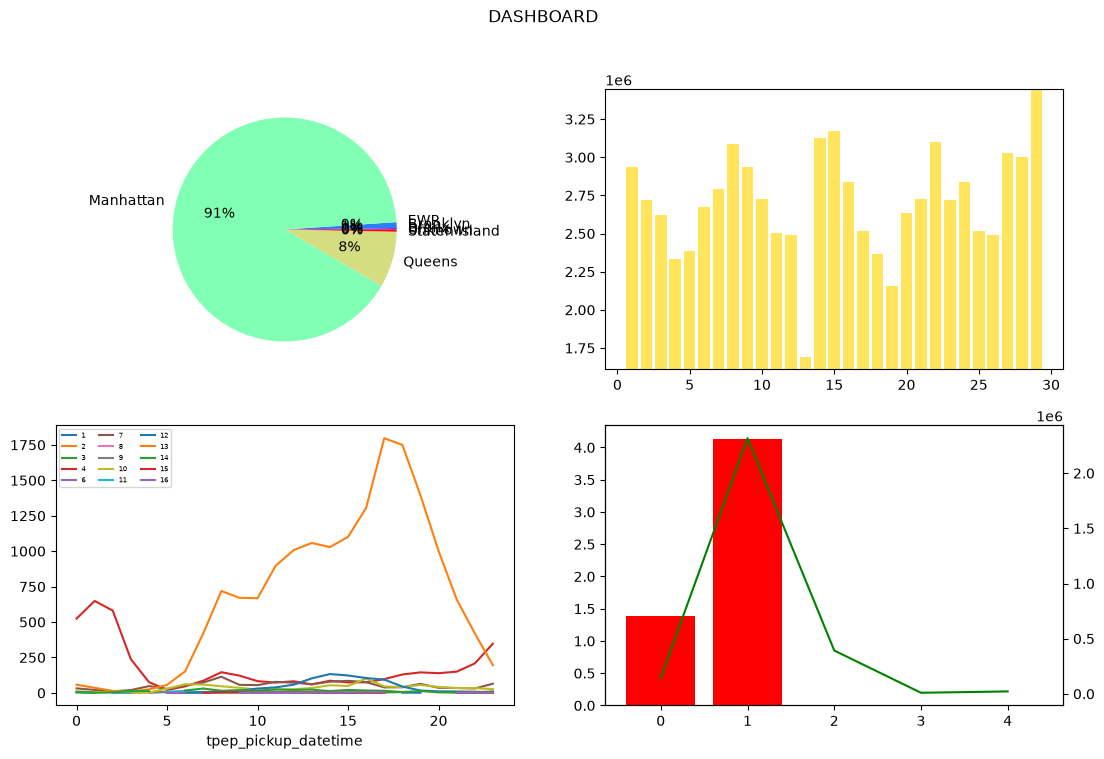

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type"]

def load_month(month: str) -> pd.DataFrame:
    df = pd.read_parquet(datasets.taxi(month), columns=COLS)
    start = pd.Timestamp(month + "-01")
    dur = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between(start, start + pd.offsets.MonthBegin(1), inclusive="left")
          & dur.between(1, 180) & df["trip_distance"].between(0.1, 100) & df["fare_amount"].between(3, 500))
    return df[ok].assign(duration_min=dur[ok])

zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
trips = load_month("2024-02")
trips["borough"] = trips["PULocationID"].map(zones.set_index("LocationID")["Borough"])

def bad_dashboard(trips):
    """The current dashboard of the operations team (do not change this function)."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    b = trips.groupby("borough").size()
    axes[0, 0].pie(b, labels=b.index, autopct="%1.0f%%", colors=plt.cm.rainbow(np.linspace(0, 1, len(b))))
    d = trips.groupby(trips["tpep_pickup_datetime"].dt.day)["total_amount"].sum()
    axes[0, 1].bar(d.index, d.values, color="#FFE45C")
    axes[0, 1].set_ylim(d.min() * 0.95, d.max())
    h = trips.groupby([trips["tpep_pickup_datetime"].dt.hour, "PULocationID"]).size().unstack().iloc[:, :15]
    h.plot(ax=axes[1, 0], legend=True)
    axes[1, 0].legend(fontsize=5, ncol=3)
    p = trips.groupby("payment_type")["tip_amount"].mean()
    ax2 = axes[1, 1].twinx()
    axes[1, 1].bar(p.index, p.values, color="red")
    ax2.plot(p.index, trips.groupby("payment_type").size(), color="green")
    fig.suptitle("DASHBOARD")
    return fig

fig = bad_dashboard(trips)
plt.show()

## Task 1: Critique

| # | Problem | Principle broken |
| :-: | :--- | :--- |
| 1 | pie chart with seven slices, several tiny | angles are hard to compare (L01); use bars |
| 2 | rainbow colours for categories | no meaning in hue order; not colour-blind safe (L03) |
| 3 | daily revenue bars with a truncated y-axis | bars must start at zero (L01) |
| 4 | yellow bars on white | contrast far below 3:1 (L03) |
| 5 | 15 unlabelled zone lines with a tiny legend of ids | spaghetti chart; legend > 7 entries; ids instead of names (L01, L17) |
| 6 | dual y-axes with red/green | dual axes suggest false relations; red/green fails colour-blind readers (L01, L03) |
| 7 | payment types shown as codes 1–4 | readers must decode numbers (L07) |
| 8 | title "DASHBOARD", no KPIs, no comparison, no definitions | dashboards need message titles, comparisons and definitions (L07, L15) |

## Task 2: KPI Definitions

In [2]:
jan = load_month("2024-01")
jan["borough"] = jan["PULocationID"].map(zones.set_index("LocationID")["Borough"])
KPIS = {
    "Trips per day": (lambda d, days: len(d) / days, "{:,.0f}", "up", "cleaned trips / days in month"),
    "Revenue per day": (lambda d, days: d["total_amount"].sum() / days, "${:,.0f}", "up", "sum of total_amount / days"),
    "Card tip rate": (lambda d, days: 100 * d.loc[d.payment_type == 1, "tip_amount"].sum() / d.loc[d.payment_type == 1, "fare_amount"].sum(),
                      "{:.1f}%", "up", "card tips / card fares"),
    "Median trip": (lambda d, days: d["duration_min"].median(), "{:.1f} min", "none", "median duration in minutes"),
}
kpi = pd.DataFrame({name: {"Feb": f(trips, 29), "Jan": f(jan, 31)} for name, (f, *_ ) in KPIS.items()}).T
kpi["change_%"] = 100 * (kpi["Feb"] / kpi["Jan"] - 1)
kpi.assign(definition=[v[3] for v in KPIS.values()]).round(2)

,Feb,Jan,change_%,definition
Trips per day,99512.07,92121.58,8.02,cleaned trips / days in month
Revenue per day,2709744.42,2516338.45,7.69,sum of total_amount / days
Card tip rate,22.62,22.64,-0.10,card tips / card fares
Median trip,12.10,11.75,2.98,median duration in minutes


## Task 3: The Redesigned Dashboard

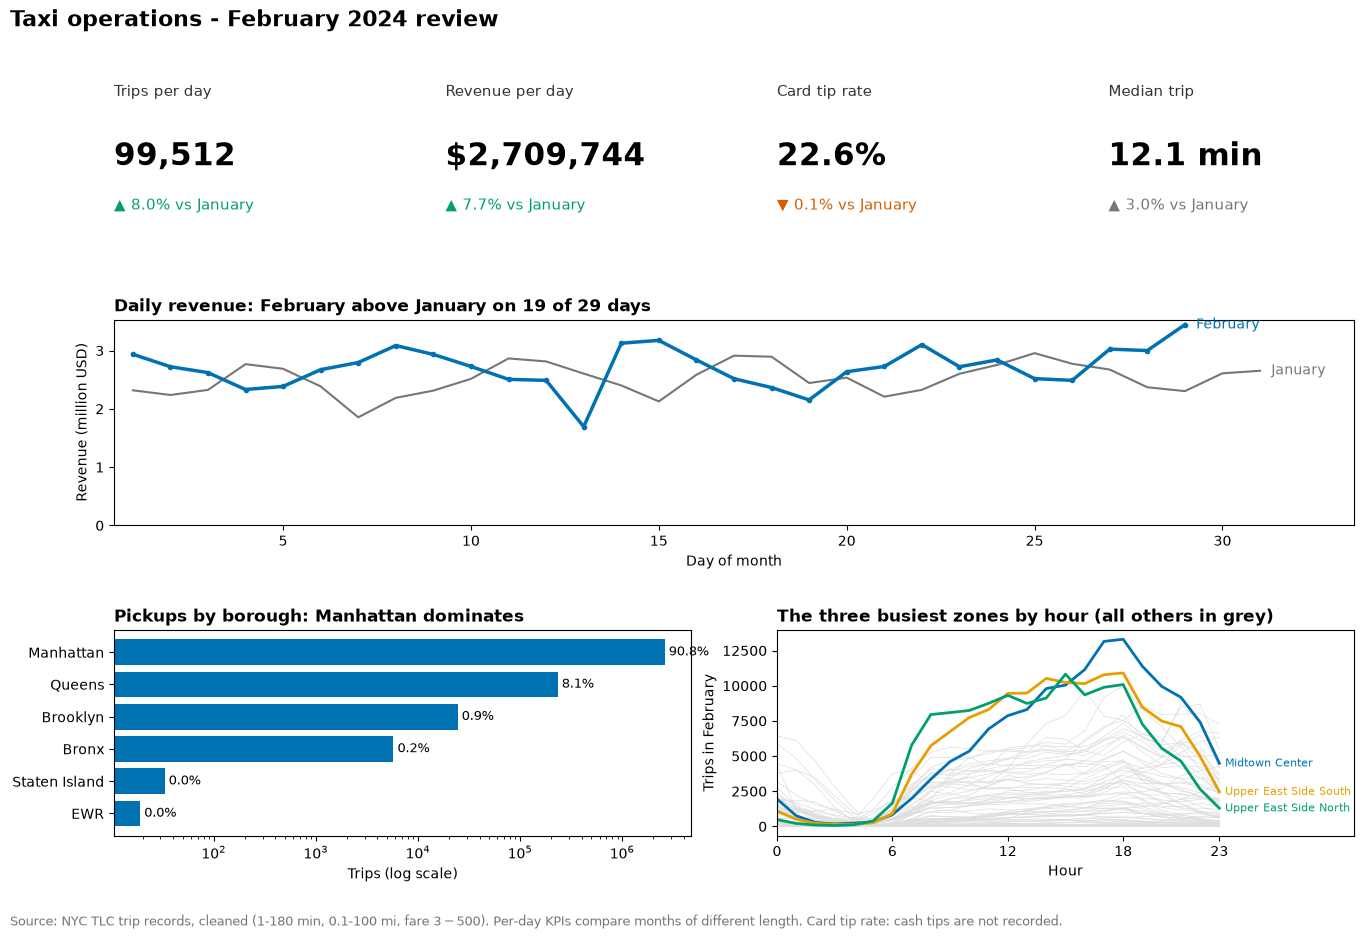

In [3]:
OKABE = {"blue": "#0072B2", "orange": "#E69F00", "grey": "#767676", "green": "#009E73", "red": "#D55E00"}
names = zones.set_index("LocationID")["Zone"]

def new_dashboard(trips, jan, kpi):
    fig = plt.figure(figsize=(16, 9.5))
    gs = fig.add_gridspec(3, 4, height_ratios=[0.7, 1.3, 1.3], hspace=0.6, wspace=0.35)
    for i, (name, row) in enumerate(kpi.iterrows()):
        ax = fig.add_subplot(gs[0, i]); ax.axis("off")
        _, fmt, good, _ = KPIS[name]
        ch = row["change_%"]
        color = OKABE["grey"] if good == "none" else (OKABE["green"] if ch > 0 else OKABE["red"])
        ax.set_title(name, loc="left", fontsize=11, color="#333333")
        ax.text(0, 0.45, fmt.format(row["Feb"]), fontsize=22, fontweight="bold", transform=ax.transAxes)
        ax.text(0, 0.05, f"{'▲' if ch > 0 else '▼'} {abs(ch):.1f}% vs January", fontsize=11, color=color, transform=ax.transAxes)

    ax = fig.add_subplot(gs[1, :])
    d_feb = trips.groupby(trips["tpep_pickup_datetime"].dt.day)["total_amount"].sum() / 1e6
    d_jan = jan.groupby(jan["tpep_pickup_datetime"].dt.day)["total_amount"].sum() / 1e6
    ax.plot(d_jan.index, d_jan.values, color=OKABE["grey"], lw=1.5)
    ax.plot(d_feb.index, d_feb.values, color=OKABE["blue"], lw=2.5, marker="o", ms=3)
    ax.text(d_feb.index[-1] + 0.3, d_feb.iloc[-1], "February", color=OKABE["blue"], va="center")
    ax.text(d_jan.index[-1] + 0.3, d_jan.iloc[-1], "January", color=OKABE["grey"], va="center")
    ax.set(ylim=(0, None), xlabel="Day of month", ylabel="Revenue (million USD)", xlim=(0.5, 33.5))
    ax.set_title(f"Daily revenue: February above January on {(d_feb > d_jan.reindex(d_feb.index)).sum()} of 29 days",
                 loc="left", fontweight="bold")

    ax = fig.add_subplot(gs[2, :2])
    b = trips.groupby("borough").size().drop(["Unknown", "N/A"], errors="ignore").sort_values()
    ax.barh(b.index, b.values, color=OKABE["blue"])
    for i, v in enumerate(b.values):
        ax.text(v, i, f" {v / b.sum():.1%}", va="center", fontsize=9)
    ax.set(xscale="log", xlabel="Trips (log scale)")
    ax.set_title("Pickups by borough: Manhattan dominates", loc="left", fontweight="bold")

    ax = fig.add_subplot(gs[2, 2:])
    h = trips.groupby([trips["tpep_pickup_datetime"].dt.hour, "PULocationID"]).size().unstack()
    top = h.sum().nlargest(3).index
    for z in h.columns:
        if z not in top:
            ax.plot(h.index, h[z], color="#DDDDDD", lw=0.5)
    for z, c in zip(top, [OKABE["blue"], OKABE["orange"], OKABE["green"]]):
        ax.plot(h.index, h[z], color=c, lw=2)
        ax.text(23.3, h[z].iloc[-1], names[z], color=c, fontsize=8, va="center")
    ax.set(xlabel="Hour", ylabel="Trips in February", xlim=(0, 30), xticks=[0, 6, 12, 18, 23])
    ax.set_title("The three busiest zones by hour (all others in grey)", loc="left", fontweight="bold")
    fig.suptitle("Taxi operations - February 2024 review", x=0.06, ha="left", fontsize=16, fontweight="bold")
    fig.text(0.06, 0.015, "Source: NYC TLC trip records, cleaned (1-180 min, 0.1-100 mi, fare $3-$500). Per-day KPIs compare months of "
             "different length. Card tip rate: cash tips are not recorded.", fontsize=9, color=OKABE["grey"])
    return fig

new = new_dashboard(trips, jan, kpi)
plt.show()

## Task 4: QA

In [4]:
import matplotlib.colors as mcolors

def contrast(a, b):
    def lum(c):
        rgb = np.array(mcolors.to_rgb(c))
        lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
        return 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]
    la, lb = sorted([lum(a), lum(b)], reverse=True)
    return (la + 0.05) / (lb + 0.05)

def lint(fig):
    issues = []
    for i, ax in enumerate(fig.axes):
        if not ax.has_data():
            continue
        if not any(ax.get_title(loc) for loc in ("left", "center", "right")):
            issues.append(f"axes {i}: no title")
        if not ax.get_xlabel():
            issues.append(f"axes {i}: no x label")
        lg = ax.get_legend()
        if lg and len(lg.get_texts()) > 7:
            issues.append(f"axes {i}: legend with {len(lg.get_texts())} entries")
        for p in ax.patches:
            if hasattr(p, "get_height") and contrast(p.get_facecolor(), ax.get_facecolor()) < 3:
                issues.append(f"axes {i}: low-contrast bars ({mcolors.to_hex(p.get_facecolor())})"); break
        if ax.patches and ax.get_ylim()[0] > 0 and not ax.get_xscale() == "log":
            issues.append(f"axes {i}: bar axis does not start at zero")
    return issues

old = bad_dashboard(trips); plt.close(old)
plt.close(new)
print("old dashboard:", len(lint(old)), "issues ->", lint(old)[:5])
print("new dashboard:", len(lint(new)), "issues ->", lint(new))

def test_revenue_reconciles():
    daily = trips.groupby(trips["tpep_pickup_datetime"].dt.day)["total_amount"].sum()
    assert len(daily) == 29 and np.isclose(daily.sum(), trips["total_amount"].sum())

def test_kpi_tile_matches_source():
    assert np.isclose(kpi.loc["Trips per day", "Feb"] * 29, len(trips))

test_revenue_reconciles(); test_kpi_tile_matches_source()
print("reconciliation tests passed")

old dashboard: 12 issues -> ['axes 0: no title', 'axes 0: no x label', 'axes 1: no title', 'axes 1: no x label', 'axes 1: low-contrast bars (#ffe45c)']
new dashboard: 0 issues -> []
reconciliation tests passed


## Task 5: Note to the Operations Manager

The new dashboard starts with four KPIs, each compared with January on a per-day basis, so a month with fewer days no longer looks worse. The daily revenue chart now starts at zero and shows January in grey for context, so you see real changes instead of exaggerated ones. Boroughs are compared with bars and percentages instead of a pie with slices too small to read. The hourly chart highlights the three busiest zones by name and shows the rest in grey, instead of fifteen unlabelled lines. Colours are colour-blind safe and every chart title states what to notice; definitions and the data source are in the footer.